In [54]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

sns.set_theme(style="whitegrid", context="notebook")
UP_BLUE, UP_RED, UP_GOLD = "#003366", "#BA0C2F", "#C69214"

# EDA


In [41]:
df = pd.read_csv("./data_20230430.csv")
df.columns = ["character_chosen", "least_favorite", "favorite_item", 
              "least_favorite_item", "favorite_track", 
              "least_favorite_track", "prefer_to_play_alone",
              "worried_of_red_shells", "love_Mario_Kart_parties",
              "get_road_rage", "have_time_to_play", "mix_courses",
              "competitive","tatical", "best_driver", "celebrate_loudly",
              "team_matches","love_the_music", "people_target_me",
              "simpathy_for_spiny_shells", "upset_if_I_loose", 
              "just_happy_to_be_involved", "welcoming_person_to_play",
              "only_play_with_favorite_character", "involve_everyone",
              "cheer_others_if_winning", "cheat"
              ]


In [42]:
print(df.shape)
df.head()

(214, 27)


,character_chosen,least_favorite,favorite_item,least_favorite_item,favorite_track,least_favorite_track,prefer_to_play_alone,worried_of_red_shells,love_Mario_Kart_parties,get_road_rage,...,love_the_music,people_target_me,simpathy_for_spiny_shells,upset_if_I_loose,just_happy_to_be_involved,welcoming_person_to_play,only_play_with_favorite_character,involve_everyone,cheer_others_if_winning,cheat
0,Bowser,Lakitu,Red Shell,Bomerang Flower,Mario Kart Stadium,N64 Rainbow Road,1,4,5,5,...,3,5,4,4,2,5,1,3,4,1
1,Yoshi,Bowser,Bullet Bill,Banana,Sweet Sweet Canyon,Rainbow Road,1,2,5,4,...,4,4,2,4,2,2,1,4,2,1
2,Toad,Donkey Kong,Red Shell,Banana,Shy Guy Falls,Sunshine Airport,1,2,5,4,...,3,1,2,2,4,5,1,4,5,2
3,Bowser,Inkling Girl,Green Shell,Spiny Shell,Mount Wario,Dolphin Shoals,1,2,5,1,...,4,4,5,1,3,4,5,4,4,1
4,Toad,Koopa Trooper,Lightning,Bomb-omb,Rainbow Road,Bowser's Castle,1,3,5,5,...,4,2,1,3,4,4,2,3,4,1


In [43]:
df = df.drop_duplicates()
print(df.shape)

(214, 27)


In [44]:
print(df["character_chosen"].value_counts())

character_chosen
Yoshi              28
Toad               15
Peach              14
Tanooki Mario      11
Pink Gold Peach    11
Shy Guy            10
Bowser              9
Luigi               9
King Boo            9
Mario               9
Daisy               8
Donkey Kong         8
Waluigi             7
Dry Bones           7
Rosalina            7
Cat Peach           6
Koopa Troopa        6
Iggy                6
Link                5
Birdo               5
Roy                 4
Ludwig              4
Morton              4
Baby Luigi          3
Wario               3
Isabelle            2
Dry Bowser          2
Bowser Jr.          2
Name: count, dtype: int64


In [45]:
print(df["character_chosen"].unique())
print(df["least_favorite"].unique())
print(df["favorite_item"].unique())
print(df["least_favorite_item"].unique())
print(df["favorite_track"].unique())
print(df["least_favorite_track"].unique())


<StringArray>
[         'Bowser',           'Yoshi',            'Toad',         'Waluigi',
           'Peach',           'Luigi',           'Daisy',        'Isabelle',
        'King Boo',     'Donkey Kong',       'Dry Bones',       'Cat Peach',
           'Mario',    'Koopa Troopa',   'Tanooki Mario',      'Dry Bowser',
         'Shy Guy',        'Rosalina', 'Pink Gold Peach',             'Roy',
            'Link',      'Baby Luigi',           'Birdo',          'Ludwig',
            'Iggy',           'Wario',      'Bowser Jr.',          'Morton']
Length: 28, dtype: str
<StringArray>
[         'Lakitu',          'Bowser',     'Donkey Kong',    'Inkling Girl',
   'Koopa Trooper',     'Metal Mario',         'Waluigi',      'Baby Peach',
           'Peach',           'Daisy',           'Wario',     'Inkling Boy',
 'Villager Female',           'Yoshi',           'Luigi',           'Mario',
      'Baby Luigi',            'Link',             'Mii',       'Dry Bones',
      'Baby Mario',      

In [46]:
numerical_features = ["prefer_to_play_alone",
              "worried_of_red_shells", "love_Mario_Kart_parties",
              "get_road_rage", "have_time_to_play", "mix_courses",
              "competitive","tatical", "best_driver", "celebrate_loudly",
              "team_matches","love_the_music", "people_target_me",
              "simpathy_for_spiny_shells", "upset_if_I_loose", 
              "just_happy_to_be_involved", "welcoming_person_to_play",
              "only_play_with_favorite_character", "involve_everyone",
              "cheer_others_if_winning", "cheat"
              ]

categorical_features = [ "least_favorite",
                        "favorite_item", "least_favorite_item",
                        "favorite_track", "least_favorite_track"]

df_encoded = pd.get_dummies(df, columns=categorical_features, drop_first=True, dtype=int)


In [47]:

print(df_encoded.shape)

(214, 144)


In [48]:
df_encoded.head()

,character_chosen,prefer_to_play_alone,worried_of_red_shells,love_Mario_Kart_parties,get_road_rage,have_time_to_play,mix_courses,competitive,tatical,best_driver,...,least_favorite_track_SNES Donut Plains 3,least_favorite_track_Shy Guy Falls,least_favorite_track_Sunshine Airport,least_favorite_track_Sweet Sweet Canyon,least_favorite_track_Thwomp Ruins,least_favorite_track_Toad Harbour,least_favorite_track_Twisted Mansion,least_favorite_track_Water Park,least_favorite_track_Wii Grumble Volcano,least_favorite_track_Wii Moo Moo Meadows
0,Bowser,1,4,5,5,4,5,5,5,4,...,0,0,0,0,0,0,0,0,0,0
1,Yoshi,1,2,5,4,5,4,5,4,2,...,0,0,0,0,0,0,0,0,0,0
2,Toad,1,2,5,4,2,5,5,5,4,...,0,0,1,0,0,0,0,0,0,0
3,Bowser,1,2,5,1,2,5,2,4,4,...,0,0,0,0,0,0,0,0,0,0
4,Toad,1,3,5,5,2,5,5,4,2,...,0,0,0,0,0,0,0,0,0,0


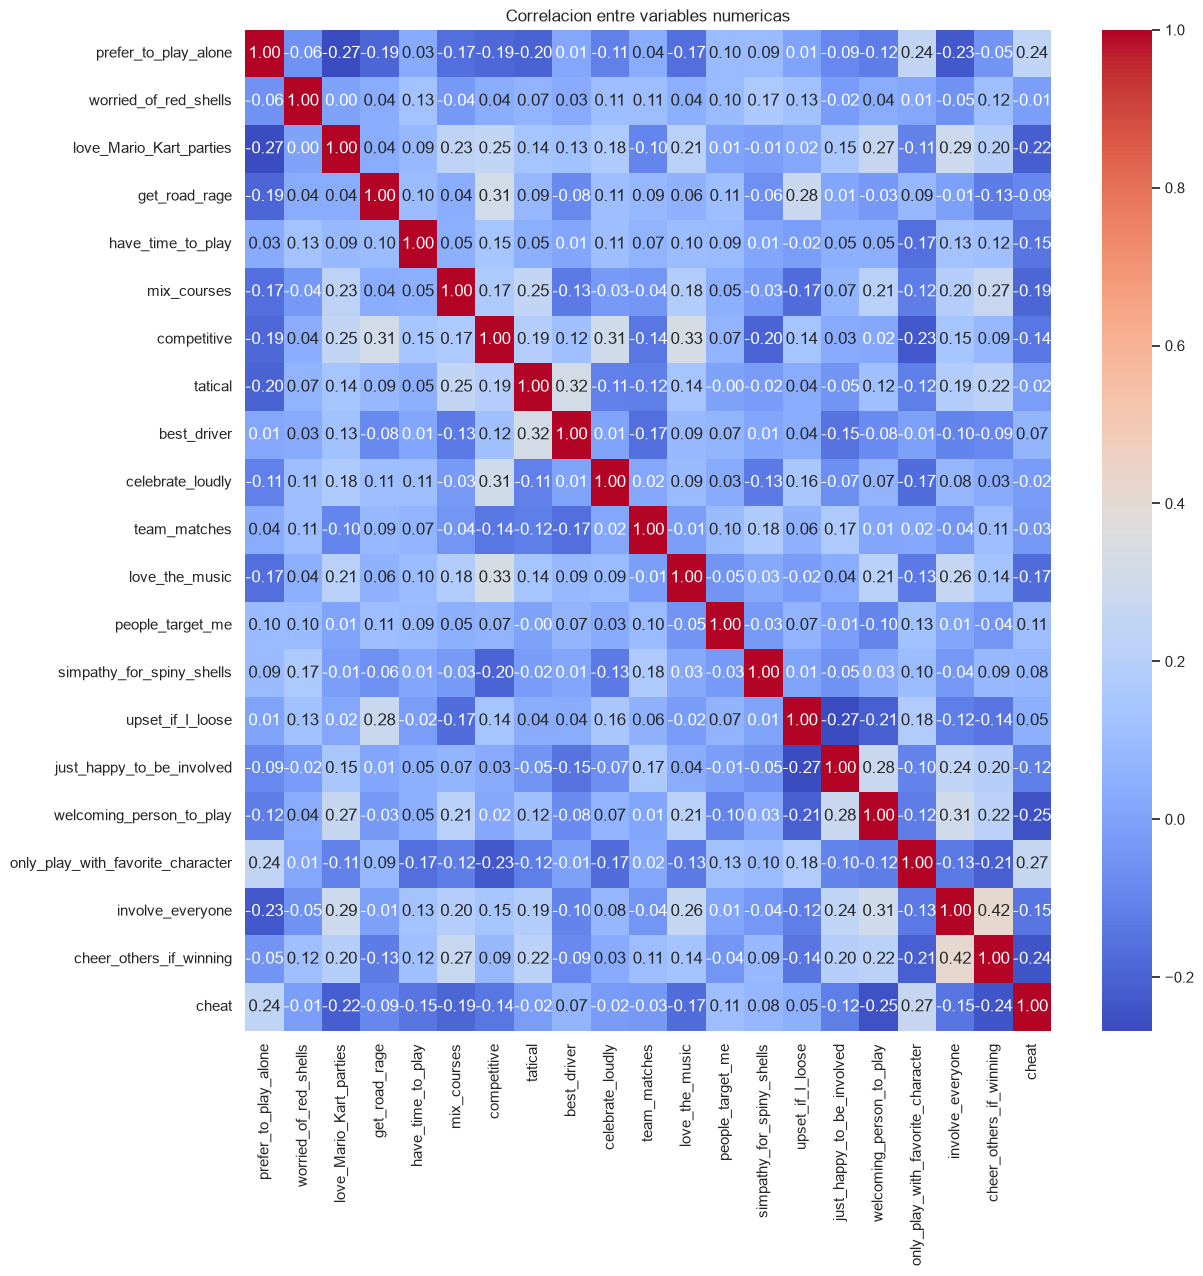

In [49]:
plt.figure(figsize=(13, 13))
sns.heatmap(df[numerical_features].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlacion entre variables numericas")
plt.show()

# MATRIZ DE DISEÑO

In [50]:
X = df_encoded.drop(columns=["character_chosen"])
y = df_encoded["character_chosen"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

# KNN

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packa

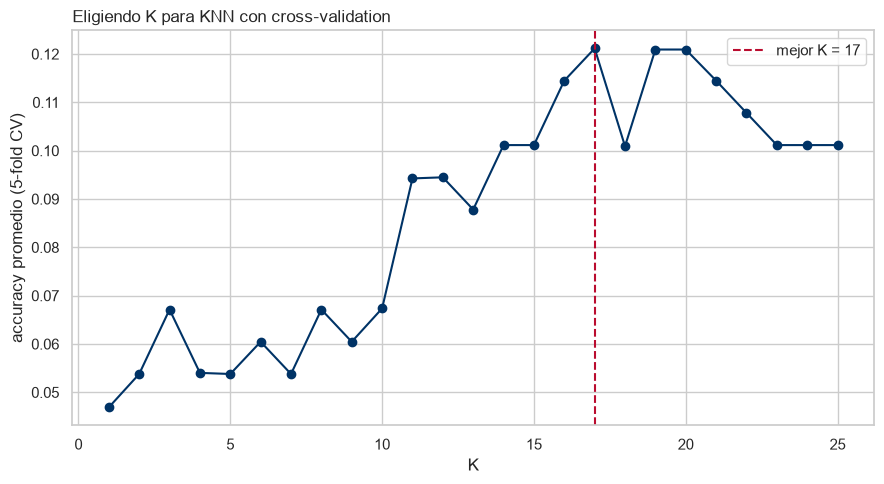

In [55]:
k_grid = range(1, 26)
cv_scores = [cross_val_score(KNeighborsClassifier(n_neighbors=k), X_train, y_train, cv=5).mean() for k in k_grid]
best_k = list(k_grid)[int(np.argmax(cv_scores))]

plt.figure(figsize=(9, 5))
plt.plot(list(k_grid), cv_scores, marker="o", color=UP_BLUE)
plt.axvline(best_k, color=UP_RED, ls="--", label=f"mejor K = {best_k}")
plt.xlabel("K")
plt.ylabel("accuracy promedio (5-fold CV)")
plt.title("Eligiendo K para KNN con cross-validation", loc="left")
plt.legend()
plt.tight_layout()
plt.show()

# Árbol